Scientific source notebook for the isolated reproduction tree. Calculation cells and saved execution objects are preserved. Narrative navigation has been adapted for this package. Use the reproduction runner and frozen-input prerequisites before executing. Historical evaluation blocks remain reused evidence; this copy does not establish independent replication.


# 03 — Liquidity, recent risk and forecast-error anatomy

**Executed amended study — reused historical evaluation blocks.**

Does liquidity improve the common risk level, differences between companies, or both, and how much remains after recent risk? B=C+R+L is specified before scores and retained even if it loses.

Read with the specified plan, operational specification and data requirements. The calculation functions below are local to this notebook; saved tables retain the comparison and sample identifiers.


## Four separately fitted models and temporal discipline

Fit C, C+L, C+R and B on identical union-input eligible company-quarter rows. Fit expanding-window pooled OLS on earlier completed outcomes only, retaining original observation weights. Estimate scaling/category maps and variance retransformation only in training. Primary target/metric: log residual volatility/MSE; equal-quarter aggregation. No future-quarter correction.


In [1]:
from pathlib import Path
import json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists(): ROOT = ROOT.parent
EXT = ROOT / 'extensions/company_risk'
OUT = EXT / 'results'; OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT / 'src'))
C = ['conventional_'+x for x in ['mkt_rf','smb','hml','rmw','cma','mom']] + ['log_issuer_cap','own_momentum','long_residual_vol_annual','french_market_beta','market_negative_increment']
def model_columns(model, liquidity):
    a,d = (60,60) if liquidity=='amihud60_dollar60' else ((252,252) if liquidity=='amihud252_dollar252' else (252,60))
    columns = C.copy()
    if model.startswith('B') or '+R' in model: columns += ['R60']
    if model.startswith('B') or '+L' in model: columns += [f'L_amihud{a}', f'L_dollar_volume{d}']
    for symbol, column in [('S','S'),('V','V_annual'),('A','A')]:
        if '+'+symbol in model: columns.append(column)
    return columns

def fit_chronological_company_models(company_features, fixed_outcomes=None, eligibility=None, model_definitions=None, frozen_training_spec=None):
    """Expanding pooled unweighted OLS; training alone determines scaling, categories and smearing.

    The original 'observation weights' are one per eligible issuer-quarter. Industry
    groups with <5 distinct training issuers pool into sector remainder. Unseen
    categories use the omitted-category intercept and are explicitly counted.
    """
    spec=model_definitions; data=company_features.copy()
    union=sorted(set(sum([model_columns(m,spec['liquidity']) for m in spec['models']],[])))
    if 'matched' in spec['run_id']: union=sorted(set(union+['R60','L_amihud60','L_amihud252','L_dollar_volume60','L_dollar_volume252','S','V_annual']))
    mask=data[union+['log_residual_vol']].notna().all(axis=1)
    sample=data.loc[mask].copy()
    sample_id=hashlib.sha256(('|'.join(sorted(sample.issuer_id.astype(str)+'|'+sample.formation_date.astype(str)))).encode()).hexdigest()[:16]
    eligible=data[['issuer_id','formation_date','exposure_window','snapshot_weight']].copy()
    eligible['comparison_id']=spec['run_id']; eligible['sample_id']=sample_id
    eligible['eligible']=mask; eligible['reason']=np.where(mask,'eligible','missing union feature or fixed outcome')
    predictions=[]; preprocessing=[]
    for formation,test in sample.groupby('formation_date',sort=True):
        train=sample[(sample.formation_date<formation)&(sample.outcome_end<=formation)]
        if train.formation_date.nunique()<8: continue
        assert train.outcome_end.max()<=formation
        for model in spec['models']:
            columns=model_columns(model,spec['liquidity'])
            mean=train[columns].mean(); scale=train[columns].std(ddof=0).replace(0,1)
            def labels(frame):
                if spec['controls']=='sector': return 'sector_'+frame.sector.astype(str)
                counts=train.groupby('industry_group').issuer_id.nunique()
                allowed=set(counts[counts>=5].index.astype(str))
                return ('industry_'+frame.industry_group.astype(str)).where(frame.industry_group.astype(str).isin(allowed),'sector_remainder_'+frame.sector.astype(str))
            train_labels=labels(train); test_labels=labels(test); categories=sorted(train_labels.unique())
            def design(frame, lab):
                dummy=np.column_stack([lab.eq(k).astype(float) for k in categories[1:]]) if len(categories)>1 else np.empty((len(frame),0))
                return np.column_stack([np.ones(len(frame)),((frame[columns]-mean)/scale).to_numpy(float),dummy])
            X=design(train,train_labels); Z=design(test,test_labels); y=train.log_residual_vol.to_numpy()
            coef=np.linalg.pinv(X.T@X,hermitian=True)@(X.T@y)
            residual=y-X@coef
            # E[variance|X] via training-only Duan retransformation: E(exp(2 residual)).
            smear=np.exp(2*residual).mean()
            pred=Z@coef
            rows=test[['issuer_id','formation_date','exposure_window','outcome_quarter','outcome_end','snapshot_weight','log_residual_vol','actual_variance','block_label']].copy()
            rows=rows.rename(columns={'log_residual_vol':'actual_log_vol'})
            rows['run_id']=spec['run_id'];rows['comparison_id']=spec['run_id'];rows['sample_id']=sample_id;rows['model_id']=model
            rows['predicted_log_vol']=pred;rows['predicted_variance']=np.maximum(np.exp(2*pred)*smear,1e-12)
            rows['score_weight']=1.;rows['training_count']=len(train); rows['training_quarters']=train.formation_date.nunique()
            rows['train_last_completed_outcome']=train.outcome_end.max(); rows['retransformation']=smear
            rows['unseen_category_rows']=(~test_labels.isin(categories)).sum()
            rows['design_rank']=np.linalg.matrix_rank(X); rows['design_parameters']=X.shape[1]
            rows['design_condition_number']=np.linalg.cond(X)
            predictions.append(rows)
            for column in columns:
                preprocessing.append(dict(run_id=spec['run_id'],model_id=model,formation_date=formation,term=column,training_mean=mean[column],training_scale=scale[column],training_count=len(train),training_end=train.outcome_end.max(),sample_id=sample_id,categories=json.dumps(categories),smearing=smear,design_rank=np.linalg.matrix_rank(X),design_parameters=X.shape[1],design_condition_number=np.linalg.cond(X),coefficient=coef[1+columns.index(column)]))
    return pd.concat(predictions,ignore_index=True),eligible,pd.DataFrame(preprocessing)


## Calibration versus differentiation: exact accounting

For e=predicted−realized log volatility, m=weighted mean(e), d=weighted mean((e−m)²), MSE=m²+d. Use the same within-quarter scoring weights. Differences in both pieces sum to the paired MSE difference. For mean quarterly percentage gains, divide each quarter component change by its own baseline MSE before equal-quarter averaging. Dispersion is not rank correlation; oracle future mean subtraction is diagnostic only.


In [2]:
def decompose_quarterly_mse(matched_predictions, score_weights=None, comparison_pairs=None):
    """Exact within-quarter MSE accounting; no oracle correction enters predictions."""
    rows=[]
    for key,g in matched_predictions.groupby(['run_id','sample_id','model_id','outcome_quarter','block_label']):
        e=g.predicted_log_vol-g.actual_log_vol; m=e.mean(); d=((e-m)**2).mean(); mse=(e**2).mean()
        assert np.isclose(mse,m*m+d,atol=1e-12)
        ratio=g.actual_variance/g.predicted_variance
        rows.append(dict(zip(['run_id','sample_id','model_id','outcome_quarter','block_label'],key))|dict(n_companies=len(g),represented_snapshot_weight=g.snapshot_weight.sum(),mse_log_vol=mse,mean_error=m,squared_mean_error=m*m,centered_error_dispersion=d,qlike_variance=(ratio-np.log(ratio)-1).mean()))
    scores=pd.DataFrame(rows);pairs=[]
    for spec in comparison_pairs:
        t=scores[scores.run_id.eq(spec['run_id'])]
        for baseline,extended in spec['pairs']:
            left=t[t.model_id.eq(baseline)];right=t[t.model_id.eq(extended)]
            joined=left.merge(right,on=['run_id','sample_id','outcome_quarter','block_label'],suffixes=('_b','_e'),validate='one_to_one')
            for _,r in joined.iterrows():
                gain=r.mse_log_vol_b-r.mse_log_vol_e; cal=r.squared_mean_error_b-r.squared_mean_error_e; disp=r.centered_error_dispersion_b-r.centered_error_dispersion_e
                assert np.isclose(gain,cal+disp,atol=1e-12)
                pairs.append(dict(run_id=spec['run_id'],comparison_id=spec['run_id'],sample_id=r.sample_id,outcome_quarter=r.outcome_quarter,block_label=r.block_label,baseline_model_id=baseline,extended_model_id=extended,metric='mse_log_vol',baseline_loss=r.mse_log_vol_b,extended_loss=r.mse_log_vol_e,absolute_gain=gain,percentage_gain=100*gain/r.mse_log_vol_b,calibration_gain=cal,dispersion_gain=disp,calibration_percentage_gain=100*cal/r.mse_log_vol_b,dispersion_percentage_gain=100*disp/r.mse_log_vol_b,qlike_gain=r.qlike_variance_b-r.qlike_variance_e))
    return scores,pd.DataFrame(pairs)


## Matched horizons and overlapping information

Repeat the four models with primary mixed L, 60/60 L and 252/252 L on common samples including R eligibility. Inspect overlap with size, recent risk and between liquidity measures. Reduced incremental liquidity value suggests overlapping information, not a causal mechanism. Do not choose L after scores.


In [3]:
def summarize_paired_company_evidence(quarterly_scores, paired_decompositions, block_labels=None, frozen_inference_spec=None):
    """Circular four-quarter blocks sampled within contiguous calendar segments.

    Intervals condition on estimated features and forecasts. Calendar gaps split
    segments; no block bridges a missing quarter. Whole cross-sections travel together.
    """
    rows=[]
    for keys,g in paired_decompositions.groupby(['run_id','baseline_model_id','extended_model_id']):
        for block,t in [('all',g),*list(g.groupby('block_label'))]:
            t=t.sort_values('outcome_quarter'); x=t.percentage_gain.to_numpy(); periods=pd.PeriodIndex(t.outcome_quarter,freq='Q').asi8
            segments=np.split(np.arange(len(t)),np.where(np.diff(periods)!=1)[0]+1)
            rng=np.random.default_rng(20261014); boot=np.zeros(2000)
            for seg in segments:
                k=min(4,len(seg)); starts=rng.integers(0,len(seg),size=(2000,int(np.ceil(len(seg)/k))))
                idx=(starts[:,:,None]+np.arange(k)).reshape(2000,-1)[:,:len(seg)]%len(seg)
                boot+=x[seg][idx].sum(axis=1)/len(x)
            rows.append(dict(zip(['run_id','baseline_model_id','extended_model_id'],keys))|dict(block_label=block,quarters=len(t),mean_percentage_gain=x.mean(),conditional_low=np.quantile(boot,.025),conditional_high=np.quantile(boot,.975),mean_absolute_gain=t.absolute_gain.mean(),mean_calibration_percentage_gain=t.calibration_percentage_gain.mean(),mean_dispersion_percentage_gain=t.dispersion_percentage_gain.mean(),mean_qlike_gain=t.qlike_gain.mean(),positive_quarter_share=(x>0).mean(),calendar_segments=len(segments),bootstrap_replications=2000,block_length=4,seed=20261014))
    return pd.DataFrame(rows)

def run_frozen_company_comparisons(features, outcomes, runs, family):
    features=features.copy()
    features['long_residual_vol_annual']=np.exp(features.long_log_residual_vol)
    output=[];elig=[];prep=[]
    for spec in runs:
        window=spec['exposure_window'];frame=features[features.exposure_window.eq(window)&features.representative_flag].merge(outcomes,on=['issuer_id','formation_date','exposure_window'],validate='one_to_one',suffixes=('','_outcome'))
        pred,e,p=fit_chronological_company_models(frame,model_definitions=spec)
        output.append(pred);elig.append(e);prep.append(p)
    predictions=pd.concat(output,ignore_index=True)
    scores,pairs=decompose_quarterly_mse(predictions,comparison_pairs=runs)
    summary=summarize_paired_company_evidence(scores,pairs)
    for name,table in [('company_predictions',predictions),('company_quarterly_scores',scores),('paired_effects',pairs),('company_inference',summary),('training_preprocessing',pd.concat(prep,ignore_index=True))]:table.to_csv(OUT/(family+'_'+name+('.csv.gz' if name=='company_predictions' else '.csv')),index=False)
    pd.concat(elig,ignore_index=True).to_csv(EXT/'data/processed'/(family+'_comparison_eligibility.csv'),index=False)
    return summary



## Effect sizes and dependence-aware uncertainty

Report simpler models, quarter-level changes, reused blocks, counts and represented weight. Resample whole cross-sections together by quarter, preserving calendar gaps, with frozen corrected circular-block settings. Intervals condition on measured exposures/fitted forecasts; six confirmation quarters are limited evidence.


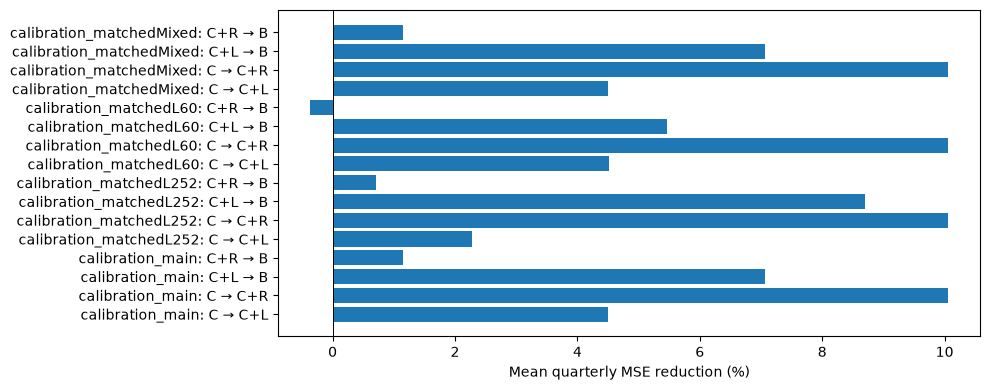

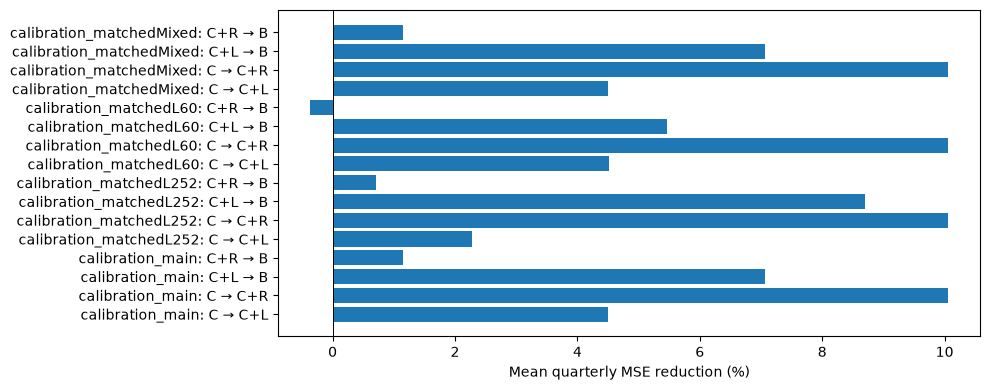

In [4]:
features=pd.read_csv(EXT/'data/processed/formation_measurements.csv',parse_dates=['formation_date'])
outcomes=pd.read_csv(EXT/'data/processed/company_outcomes.csv',parse_dates=['formation_date','outcome_end'])
manifest=json.loads((EXT/'specification/comparison_manifest.json').read_text())
runs=[s for s in manifest['runs'] if 'calibration' in s['family']]
runs.append(dict(runs[0],run_id='calibration_matchedMixed'))
summary=run_frozen_company_comparisons(features,outcomes,runs,'calibration')
summary=summary[summary.run_id.str.startswith('calibration')]
display(summary[summary.block_label.eq('all')])


In [5]:
display(summary[summary.run_id.eq('calibration_main')])

,run_id,baseline_model_id,extended_model_id,block_label,quarters,mean_percentage_gain,conditional_low,conditional_high,mean_absolute_gain,mean_calibration_percentage_gain,mean_dispersion_percentage_gain,mean_qlike_gain,positive_quarter_share,calendar_segments,bootstrap_replications,block_length,seed
0,calibration_main,C,C+L,all,26,4.503609,2.223759,6.870839,0.003385,0.509076,3.994533,0.003990,0.730769,1,2000,4,20261014
1,calibration_main,C,C+L,confirmation,6,10.026087,6.397871,14.294399,0.011609,7.311781,2.714305,0.021616,1.000000,1,2000,4,20261014
2,calibration_main,C,C+L,development,12,2.497439,-1.523577,7.390989,-0.000097,-2.243481,4.740920,-0.005856,0.500000,1,2000,4,20261014
3,calibration_main,C,C+L,validation,8,3.371004,2.896092,3.845917,0.002439,-0.464117,3.835121,0.005539,0.875000,1,2000,4,20261014
4,calibration_main,C,C+R,all,26,10.056970,7.190805,13.448629,0.009000,2.838581,7.218389,0.012923,0.884615,1,2000,4,20261014
5,calibration_main,C,C+R,confirmation,6,15.710866,10.007855,22.374552,0.017491,8.952160,6.758706,0.033278,1.000000,1,2000,4,20261014
6,calibration_main,C,C+R,development,12,9.452379,4.175096,15.842623,0.007572,1.106210,8.346169,0.004961,0.750000,1,2000,4,20261014
7,calibration_main,C,C+R,validation,8,6.723435,4.610324,8.836546,0.004774,0.851955,5.871480,0.009600,1.000000,1,2000,4,20261014
8,calibration_main,C+L,B,all,26,7.060432,4.999254,9.276934,0.006200,3.368662,3.691770,0.010655,0.846154,1,2000,4,20261014
9,calibration_main,C+L,B,confirmation,6,9.041122,3.875459,14.553853,0.008499,4.918165,4.122957,0.014936,0.833333,1,2000,4,20261014


## Findings and interpretation


## Bridge through the study

Previous: 02 Measurements supplies C/R/L without redefining residual outcomes.

Next: 04 Semiconductor representation tests S and V against the predetermined B, refitted on that set’s eligible sample.


In [6]:
display(summary)

,run_id,baseline_model_id,extended_model_id,block_label,quarters,mean_percentage_gain,conditional_low,conditional_high,mean_absolute_gain,mean_calibration_percentage_gain,mean_dispersion_percentage_gain,mean_qlike_gain,positive_quarter_share,calendar_segments,bootstrap_replications,block_length,seed
0,calibration_main,C,C+L,all,26,4.503609,2.223759,6.870839,0.003385,0.509076,3.994533,0.003990,0.730769,1,2000,4,20261014
1,calibration_main,C,C+L,confirmation,6,10.026087,6.397871,14.294399,0.011609,7.311781,2.714305,0.021616,1.000000,1,2000,4,20261014
2,calibration_main,C,C+L,development,12,2.497439,-1.523577,7.390989,-0.000097,-2.243481,4.740920,-0.005856,0.500000,1,2000,4,20261014
3,calibration_main,C,C+L,validation,8,3.371004,2.896092,3.845917,0.002439,-0.464117,3.835121,0.005539,0.875000,1,2000,4,20261014
4,calibration_main,C,C+R,all,26,10.056970,7.190805,13.448629,0.009000,2.838581,7.218389,0.012923,0.884615,1,2000,4,20261014
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,calibration_matchedMixed,C+L,B,validation,8,4.914341,2.790611,7.038072,0.003362,2.691807,2.222535,0.007110,0.750000,1,2000,4,20261014
60,calibration_matchedMixed,C+R,B,all,26,1.147587,0.297576,1.924203,0.000585,0.927467,0.220119,0.001721,0.730769,1,2000,4,20261014
61,calibration_matchedMixed,C+R,B,confirmation,6,2.784799,0.810771,4.778638,0.002618,3.294211,-0.509412,0.003274,0.833333,1,2000,4,20261014
62,calibration_matchedMixed,C+R,B,development,12,0.109553,-1.140495,1.321836,-0.000726,-0.560319,0.669872,0.000060,0.666667,1,2000,4,20261014
